<a href="https://colab.research.google.com/github/ranimiftah12345678/PCVK26_22_Ranimiftah/blob/main/Modul7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Rani Miftahus Saadah'
NIM  = '24410720057'
N     = int(NIM[-3:])
PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L':    2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Rani Miftahus Saadah
NIM    : 24410720057 | N = 57
bins   : 16
clip   : 2.0
tile   : 3
L      : 2
WAKTU  : 2026-10-24 19:09:36 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 8896e55d9edb693d


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
BASE = '/content/drive/MyDrive/PCVK 244107020057/'
IMAGES_BASE = BASE

In [5]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

##TUGAS INDIVIDU

Soal 3: Global Threshold manual (T = 200)

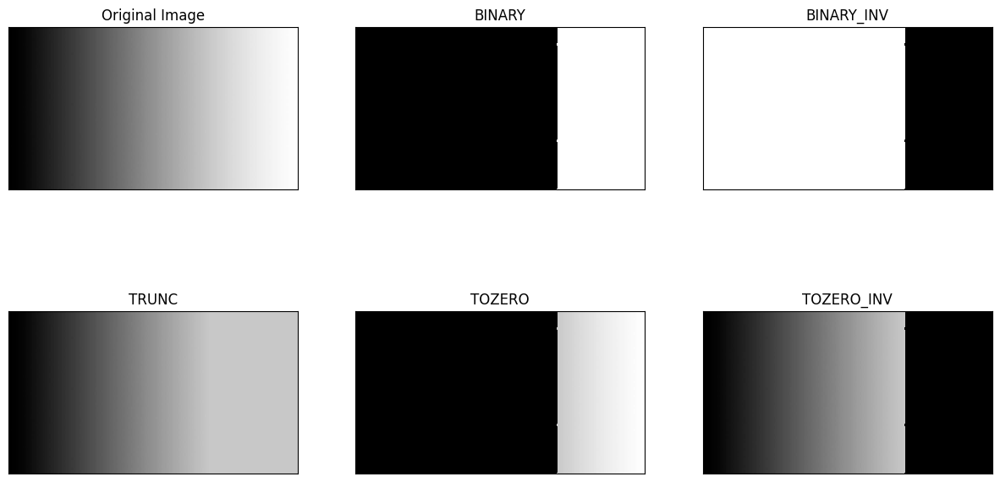

BINARY      sama dengan OpenCV: True
BINARY_INV  sama dengan OpenCV: True
TRUNC       sama dengan OpenCV: True
TOZERO      sama dengan OpenCV: True
TOZERO_INV  sama dengan OpenCV: True


In [12]:
filename = (BASE + 'gradient.jpg')
gradient = cv.imread(filename)
assert gradient is not None, f'File tidak terbaca: {filename}'
img = cv.cvtColor(gradient, cv.COLOR_BGR2GRAY)
thresh, maxval = 200, 255

JENIS = {
    'BINARY':     lambda s, t, m: np.where(s > t, m, 0),   # > T -> maxval, selain itu 0
    'BINARY_INV': lambda s, t, m: np.where(s > t, 0, m),   # > T -> 0, selain itu maxval
    'TRUNC':      lambda s, t, m: np.where(s > t, t, s),   # > T -> T, selain itu asli
    'TOZERO':     lambda s, t, m: np.where(s > t, s, 0),   # > T -> asli, selain itu 0
    'TOZERO_INV': lambda s, t, m: np.where(s > t, 0, s),   # > T -> 0, selain itu asli
}
hasil = {k: f(img, thresh, maxval).astype(np.uint8) for k, f in JENIS.items()}

judul = ['Original Image'] + list(hasil.keys())
gambar = [img] + list(hasil.values())
plt.figure(figsize=(15, 8))
for i, (j, g) in enumerate(zip(judul, gambar)):
    plt.subplot(2, 3, i+1)
    plt.imshow(g, 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(j); plt.xticks([]); plt.yticks([])
plt.show()

# Verifikasi (hanya pembanding, bukan bagian solusi)
FLAG = {'BINARY': cv.THRESH_BINARY, 'BINARY_INV': cv.THRESH_BINARY_INV, 'TRUNC': cv.THRESH_TRUNC,
        'TOZERO': cv.THRESH_TOZERO, 'TOZERO_INV': cv.THRESH_TOZERO_INV}
for k, flag in FLAG.items():
    _, ref = cv.threshold(img, thresh, maxval, flag)
    print(f'{k:11s} sama dengan OpenCV: {np.array_equal(hasil[k], ref)}')

Soal 4: Adaptive Mean & Gaussian manual (Sudoku)

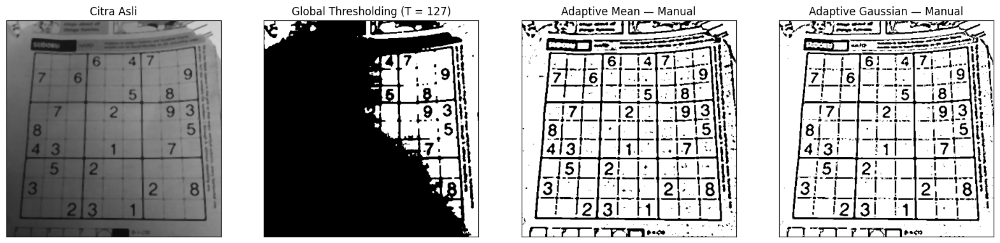

Kemiripan Adaptive Mean     dgn OpenCV: 98.46%
Kemiripan Adaptive Gaussian dgn OpenCV: 98.61%


In [13]:
filename = (BASE + 'sudoku-original.jpg')
sudoku = cv.imread(filename)
assert sudoku is not None, f'File tidak terbaca: {filename}'
gray0 = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

def median_manual(g, k=5):
    pad = k // 2
    gp = np.pad(g, pad, mode='edge')
    H, W = g.shape
    tumpukan = np.stack([gp[dy:dy+H, dx:dx+W] for dy in range(k) for dx in range(k)], axis=0)
    return np.median(tumpukan, axis=0).astype(np.uint8)

gray = median_manual(gray0, 5)

# Global threshold manual (T = 127)
def global_manual(g, t=127):
    return np.where(g > t, 255, 0).astype(np.uint8)

# Rata-rata lokal berbobot: jendela digeser, tanpa fungsi filter siap pakai
def ambang_lokal(g, kernel):
    b = kernel.shape[0]
    pad = b // 2
    gp = np.pad(g.astype(np.float64), pad, mode='edge')   # replikasi tepi
    H, W = g.shape
    lokal = np.zeros((H, W))
    for dy in range(b):
        for dx in range(b):
            lokal += kernel[dy, dx] * gp[dy:dy+H, dx:dx+W]
    return lokal

def gaussian_kernel(size=11, sigma=2):
    pusat = size // 2
    ax = np.arange(-pusat, pusat + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()               # jumlah bobot = 1

def adaptive_mean_manual(g, block_size=11, C=2):
    kernel = np.ones((block_size, block_size)) / (block_size ** 2)
    T = ambang_lokal(g, kernel) - C            # T(x,y) = mean lokal - C
    return np.where(g > T, 255, 0).astype(np.uint8)

def adaptive_gaussian_manual(g, block_size=11, sigma=2, C=2):
    kernel = gaussian_kernel(block_size, sigma)
    T = ambang_lokal(g, kernel) - C            # T(x,y) = mean Gaussian - C
    return np.where(g > T, 255, 0).astype(np.uint8)

th_global = global_manual(gray, 127)
th_mean   = adaptive_mean_manual(gray, 11, 2)
th_gauss  = adaptive_gaussian_manual(gray, 11, 2, 2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
hasil4 = [gray, th_global, th_mean, th_gauss]
plt.figure(figsize=(20, 5.5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(hasil4[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.show()

# Verifikasi (pembanding saja): kemiripan dengan OpenCV
ref_m = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
ref_g = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
print(f'Kemiripan Adaptive Mean     dgn OpenCV: {(ref_m == th_mean).mean()*100:.2f}%')
print(f'Kemiripan Adaptive Gaussian dgn OpenCV: {(ref_g == th_gauss).mean()*100:.2f}%')

Soal 5A: Otsu manual (Lena low contrast)

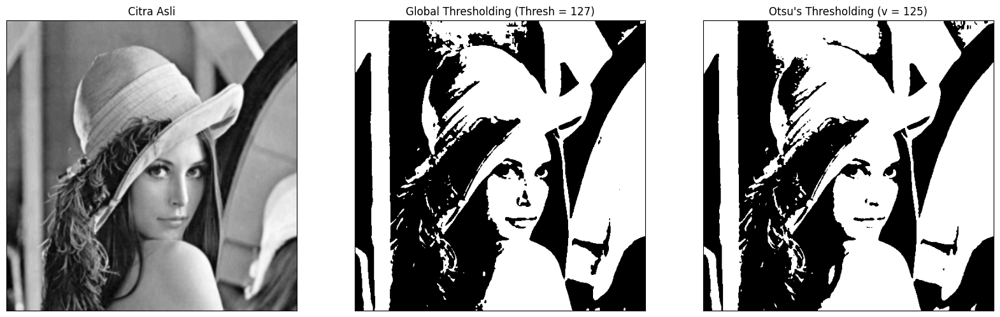

Threshold Otsu manual  : 125
Threshold Otsu library : 124.0


In [15]:
filename = (BASE + 'lena_lc.jpg')
lena = cv.imread(filename, 0)
assert lena is not None, f'File tidak terbaca: {filename}'
blur = cv.GaussianBlur(lena, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh, final_value = -1, -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t]); pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:              # lewati kelas kosong
            continue
        Wb, Wf = pcb * mean_weight, pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2    # between-class variance
        if value > final_value:
            final_thresh, final_value = t, value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i]); plt.xticks([]), plt.yticks([])
plt.show()

ret2, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Threshold Otsu manual  :', otsu_thresh)
print('Threshold Otsu library :', ret2)

min = 97 | max = 157


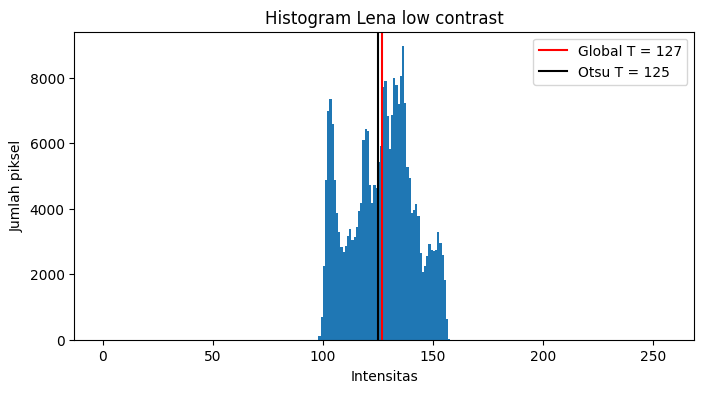

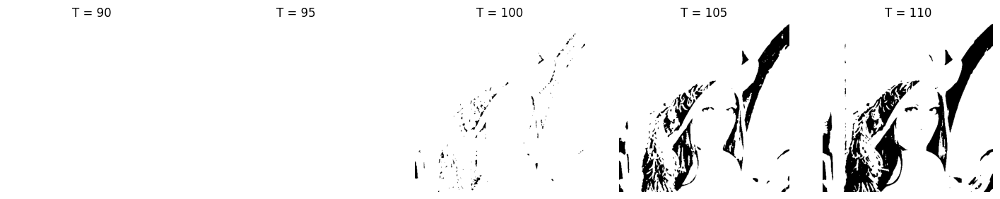

In [16]:
print('min =', blur.min(), '| max =', blur.max())

plt.figure(figsize=(8, 4))
plt.hist(blur.ravel(), bins=256, range=(0, 256))
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T = {otsu_thresh}')
plt.legend(); plt.title('Histogram Lena low contrast')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah piksel'); plt.show()

plt.figure(figsize=(18, 3.5))
for i, t in enumerate([90, 95, 100, 105, 110]):
    _, r = cv.threshold(blur, t, 255, cv.THRESH_BINARY)
    plt.subplot(1, 5, i+1); plt.imshow(r, 'gray', vmin=0, vmax=255)
    plt.title(f'T = {t}'); plt.axis('off')
plt.show()

Seluruh intensitas citra Lena low contrast hanya berada di rentang 85–108, sehingga
semua batang histogram berada di kiri garis merah T = 127. Aturan BINARY adalah
"piksel > T menjadi 255". Karena tidak ada piksel yang > 127, semuanya menjadi 0 (hitam).
Agar Lena masih terlihat, T harus berada DI DALAM rentang histogram (85 < T < 108),
misalnya 90–100, dengan nilai terbaik mendekati hasil Otsu (T ≈ 92–93). T = 110 gagal
karena sudah di luar rentang (hitam lagi).

Soal 5B: Otsu vs global pada KTP sendiri

Threshold Otsu KTP : 166


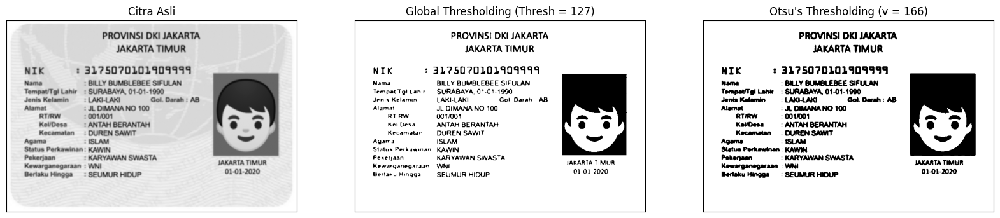

In [19]:
filename = (BASE + 'ktp_fulan.jpg')
ktp = cv.imread(filename)
assert ktp is not None, f'File tidak terbaca: {filename}'
ktp_gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)

thresh = 127
ret, g127 = cv.threshold(ktp_blur, thresh, 255, cv.THRESH_BINARY)
ktp_otsu, ktp_t = otsu(ktp_blur)
print('Threshold Otsu KTP :', ktp_t)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', "Otsu's Thresholding (v = " + str(ktp_t) + ")"]
citra_ktp = [ktp_blur, g127, ktp_otsu]
plt.figure(figsize=(20, 15))
for i in range(3):
    plt.subplot(1, 3, i+1), plt.imshow(citra_ktp[i], 'gray')
    plt.title(titles[i]); plt.xticks([]), plt.yticks([])
plt.show()


Soal 6A: Region Growing manual (data.coins)

Dalam koin  seed (baris, kolom) = (36, 43) | intensitas seed = 159
Latar       seed (baris, kolom) = (5, 5) | intensitas seed = 133
Tepi koin   seed (baris, kolom) = (36, 53) | intensitas seed = 128


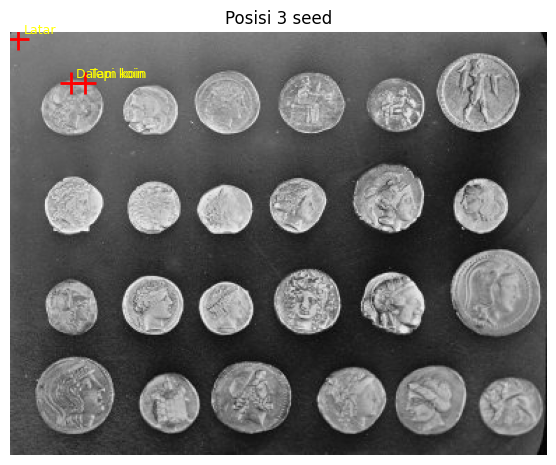

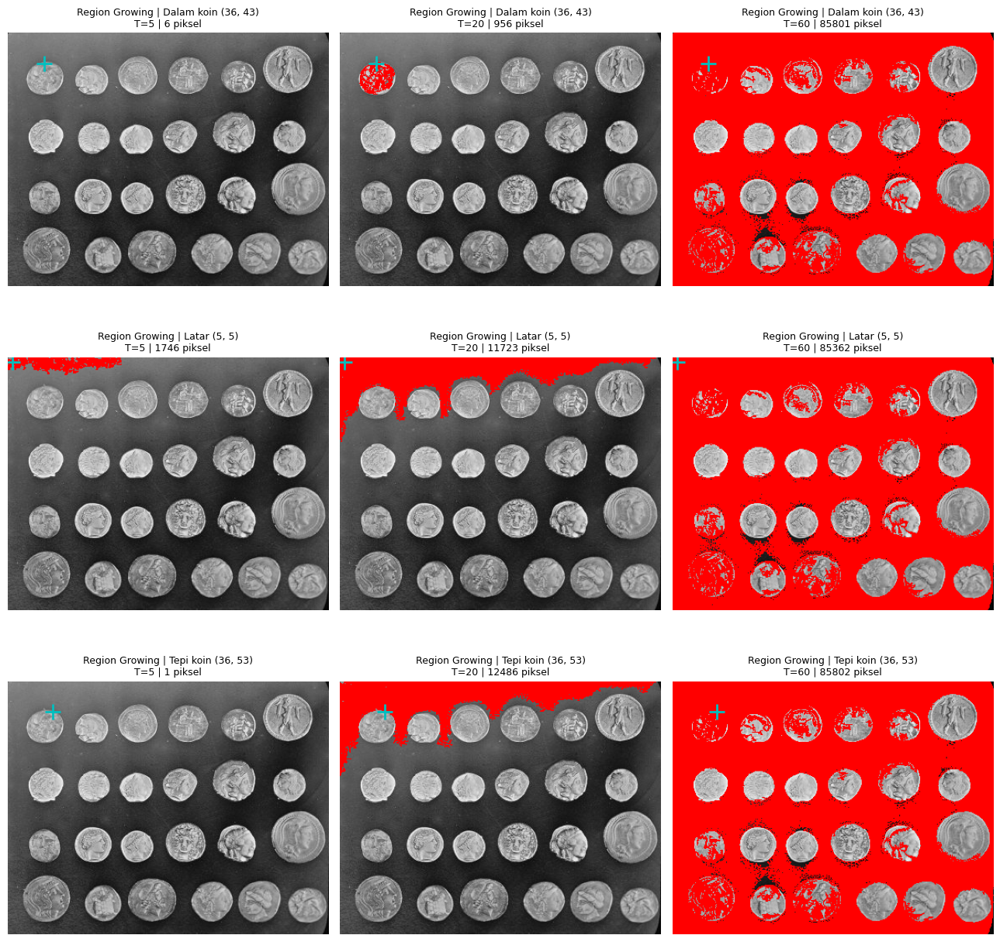

In [20]:
gray_c = data.coins()                       # grayscale 303 x 384

def region_growing(img, seed, T):
    """4-tetangga. Piksel q masuk region jika |I(q) - rata-rata region| < T."""
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    mask[seed] = True
    antrean = deque([seed])
    total, jumlah = float(img[seed]), 1
    while antrean:
        r, c = antrean.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w and not mask[rr, cc]:
                if abs(float(img[rr, cc]) - total / jumlah) < T:
                    mask[rr, cc] = True
                    antrean.append((rr, cc))
                    total += float(img[rr, cc]); jumlah += 1
    return mask

def cari_seed_tepi(img, seed_dalam, jangkauan=40):
    """Titik tepi koin = lokasi perubahan intensitas terbesar di baris seed, arah kanan."""
    r, c = seed_dalam
    garis = img[r, c:c + jangkauan].astype(float)
    halus = np.convolve(garis, np.ones(3) / 3, mode='valid')   # buang efek ujung
    idx = int(np.argmax(np.abs(np.diff(halus)))) + 1
    return (r, c + idx + 1)

seed_dalam = (36, 43)
SEEDS = {'Dalam koin': seed_dalam,
         'Latar': (5, 5),
         'Tepi koin': cari_seed_tepi(gray_c, seed_dalam)}
TS = [5, 20, 60]

# Cek posisi seed + intensitas seed
for nm, s in SEEDS.items():
    print(f'{nm:11s} seed (baris, kolom) = {s} | intensitas seed = {gray_c[s]}')
plt.figure(figsize=(7, 5.5))
plt.imshow(gray_c, 'gray')
for nm, s in SEEDS.items():
    plt.plot(s[1], s[0], 'r+', markersize=16, markeredgewidth=2)
    plt.text(s[1] + 4, s[0] - 4, nm, color='yellow', fontsize=9)
plt.title('Posisi 3 seed'); plt.axis('off'); plt.show()

def tampil_grid(fungsi, judul):
    base_rgb = np.stack([gray_c] * 3, axis=-1)
    plt.figure(figsize=(13, 13))
    jumlah_px, k = {}, 1
    for nm, s in SEEDS.items():
        for T in TS:
            m = fungsi(s, T)
            ov = base_rgb.copy(); ov[m] = [255, 0, 0]
            plt.subplot(3, 3, k); k += 1
            plt.imshow(ov)
            plt.plot(s[1], s[0], 'c+', markersize=14, markeredgewidth=2)
            plt.title(f'{judul} | {nm} {s}\nT={T} | {m.sum()} piksel', fontsize=9)
            plt.axis('off')
            jumlah_px[(nm, T)] = int(m.sum())
    plt.tight_layout(); plt.show()
    return jumlah_px

jumlah_manual = tampil_grid(lambda s, T: region_growing(gray_c, s, T), 'Region Growing')

Soal 6B: skimage.segmentation.flood()

Seed (121, 63) | intensitas seed: 224 | piksel region: 177


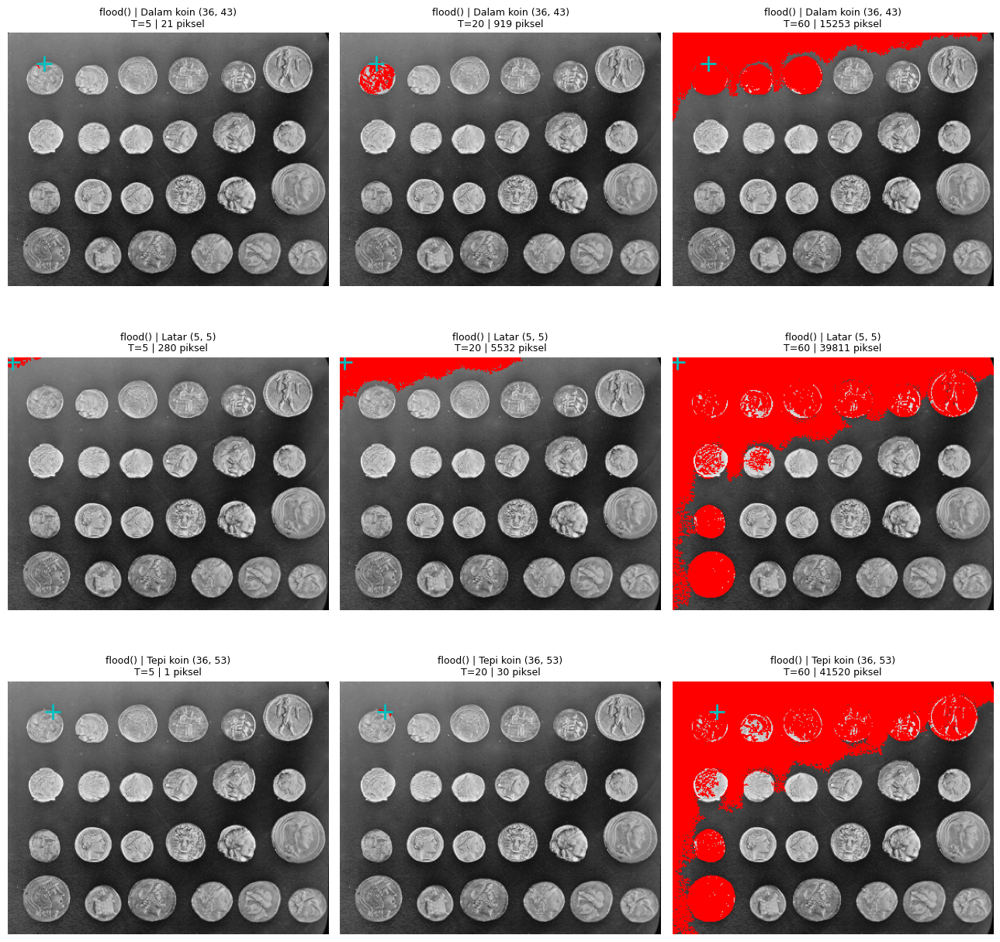

,Seed,T,Piksel (manual),Piksel (flood)
0,Dalam koin,5,6,21
1,Dalam koin,20,956,919
2,Dalam koin,60,85801,15253
3,Latar,5,1746,280
4,Latar,20,11723,5532
5,Latar,60,85362,39811
6,Tepi koin,5,1,1
7,Tepi koin,20,12486,30
8,Tepi koin,60,85802,41520


In [21]:
seed = (121, 63)
region = flood(gray_c, seed_point=seed, tolerance=20, connectivity=1)   # 4 tetangga
print(f'Seed {seed} | intensitas seed: {gray_c[seed]} | piksel region: {region.sum()}')

# Grid 3x3 yang sama dengan Sel 8, tetapi memakai flood()
jumlah_flood = tampil_grid(
    lambda s, T: flood(gray_c, seed_point=s, tolerance=T, connectivity=1), 'flood()')

# Perbandingan manual vs flood
baris = [{'Seed': nm, 'T': T,
          'Piksel (manual)': n, 'Piksel (flood)': jumlah_flood[(nm, T)]}
         for (nm, T), n in jumlah_manual.items()]
display(pd.DataFrame(baris))

Soal 7: hanya warna biru (K-Means + HSV)

,Cluster,RGB,H,S,V,Piksel,Termasuk biru
0,0,"(135, 147, 155)",102,33,155,9320,True
1,1,"(218, 239, 248)",99,31,248,122781,True
2,2,"(15, 16, 17)",105,30,17,8469,False
3,3,"(215, 70, 51)",3,195,215,10914,False
4,4,"(195, 224, 244)",102,51,244,115445,True
5,5,"(239, 210, 172)",17,71,239,8831,False
6,6,"(252, 254, 254)",90,2,254,25231,False
7,7,"(59, 60, 63)",113,16,63,16861,False


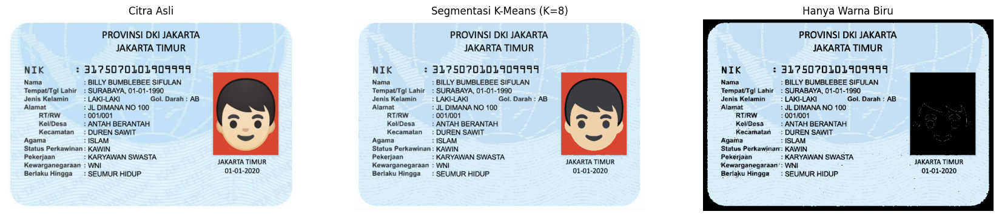

In [25]:
from sklearn.cluster import KMeans

filename = (BASE + 'ktp_fulan.jpg')
ktp_bgr = cv.imread(filename)
assert ktp_bgr is not None, f'File tidak terbaca: {filename}'
rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)

Z = np.float32(rgb.reshape((-1, 3)))

K = 8
FIT_SEMUA = False          # True = fit pada semua piksel (persis jobsheet, lebih lambat)
if FIT_SEMUA:
    data_fit = Z
else:
    rng = np.random.default_rng(42)
    data_fit = Z[rng.choice(len(Z), size=min(50000, len(Z)), replace=False)]

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(data_fit)
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels].reshape(rgb.shape)

# Ambil piksel biru dari citra hasil K-Means
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

hanya_biru = np.zeros_like(segmented_img)                 # latar HITAM
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]

# Info tiap cluster
info = []
for i in range(K):
    h_, s_, v_ = cv.cvtColor(centers[i].reshape(1, 1, 3), cv.COLOR_RGB2HSV)[0, 0]
    info.append({'Cluster': i, 'RGB': tuple(int(v) for v in centers[i]),
                 'H': int(h_), 'S': int(s_), 'V': int(v_),
                 'Piksel': int((labels == i).sum()),
                 'Termasuk biru': bool(85 <= h_ <= 130 and s_ >= 25 and v_ >= 40)})
display(pd.DataFrame(info))

plt.figure(figsize=(21, 6))
for i, (im, jd) in enumerate([(rgb, 'Citra Asli'),
                              (segmented_img, f'Segmentasi K-Means (K={K})'),
                              (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i+1); plt.imshow(im); plt.title(jd); plt.axis('off')
plt.show()


##TUGAS KELOMPOK

Instal Tesseract

In [26]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122806 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
ind
osd


Konfigurasi dan data anggota

In [40]:
import re
import os
import difflib
import pytesseract
from pytesseract import Output
from difflib import SequenceMatcher

LANG, PSM = 'ind', 6
CONF_MIN = 60          # kotak hijau hanya untuk confidence > 60
LEBAR = 1600           # semua citra diseragamkan ke lebar 1600 px
AD_BLOCK, AD_C = 51, 15   # parameter Adaptive Thresholding (blockSize harus ganjil)
MIN_MIRIP = 0.6        # kata dianggap "terbaca (salah)" hanya bila kemiripan >= 0.6

ANGGOTA = {
    'Anggota 1': {'file': BASE + 'Rani.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'BLITAR', 'PEREMPUAN',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
    'Anggota 2': {'file': BASE + 'Rafa.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'JEMBER', 'LAKI-LAKI',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
    'Anggota 3': {'file': BASE + 'Julian.jpeg',
                  'acuan': ['PROVINSI', 'JAWA TIMUR', 'KABUPATEN', 'PROBOLINGGO', 'LAKI-LAKI',
                            'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP']},
}


for nama, a in ANGGOTA.items():
    assert len(a['acuan']) == 10, f'{nama}: acuan harus tepat 10 item'
    assert not any(r.startswith('ISI_') for r in a['acuan']), \
        f'{nama}: ganti item ISI_... dengan tulisan asli di KTP-nya'

METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']
KOLOM = {'Berwarna asli': 'OCR citra berwarna',
         'Segmentasi Otsu': 'OCR Otsu',
         'Segmentasi Adaptive': 'OCR Adaptive'}
LABEL = {'Berwarna asli': 'Berwarna', 'Segmentasi Otsu': 'Otsu', 'Segmentasi Adaptive': 'Adaptive'}

Fungsi-fungsi OCR

In [41]:
def siapkan_tiga_citra(path):
    bgr = cv.imread(path)
    assert bgr is not None, f'Gagal membaca {path}'
    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)), interpolation=cv.INTER_CUBIC)

    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)                          # grayscale dulu
    _, otsu_img = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, AD_BLOCK, AD_C)
    return {'Berwarna asli': bgr, 'Segmentasi Otsu': otsu_img, 'Segmentasi Adaptive': adaptive}

def jalankan_ocr(img):
    rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    cfg = f'--oem 3 --psm {PSM}'
    teks = pytesseract.image_to_string(rgb, lang=LANG, config=cfg)
    data_ocr = pytesseract.image_to_data(rgb, lang=LANG, config=cfg, output_type=Output.DICT)
    return teks, data_ocr

def rata_conf(d):
    c = [float(cf) for cf, t in zip(d['conf'], d['text']) if t.strip() and float(cf) >= 0]
    return float(np.mean(c)) if c else 0.0

def gambar_kotak(img, d):
    kanvas = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    n = 0
    for i, t in enumerate(d['text']):
        if t.strip() and any(ch.isalnum() for ch in t) and float(d['conf'][i]) > CONF_MIN:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n += 1
    return kanvas, n

def _bersih(t):
    return re.sub(r'^\W+|\W+$', '', t.strip())

def baca_item(item, teks):
    tok = [t for t in (_bersih(x) for x in teks.split()) if t]
    n, target = len(item.split()), item.upper()
    terbaik, skor = '', 0.0
    for k in range(max(1, n - 1), n + 3):
        for i in range(len(tok) - k + 1):
            cand = ' '.join(tok[i:i + k]).upper()
            s = SequenceMatcher(None, cand, target).ratio()
            if s > skor:
                terbaik, skor = cand, s
    if terbaik == target:
        return item, True
    if skor >= MIN_MIRIP:
        return terbaik, False
    return '(tidak terbaca)', False

def jenis_salah(item, baca):
    if baca == '(tidak terbaca)':
        return 'teks tidak terbaca'
    a, b = item.upper(), baca.upper()
    if a in b:
        return 'kata menyatu dengan teks di sekitarnya'
    if len(a) == len(b):
        return 'huruf/angka tertukar (' + ', '.join(f'{x}->{y}' for x, y in zip(a, b) if x != y) + ')'
    return 'huruf/angka hilang' if len(b) < len(a) else 'karakter tambahan/salah baca'

def sensor(teks):
    hasil = []
    for b in teks.splitlines():
        if re.match(r'\W*nik\b', b.strip(), re.I):
            b = 'NIK : [DISENSOR]'
        hasil.append(re.sub(r'\d{10,}', '[DISENSOR]', b))
    return '\n'.join(l for l in hasil if l.strip())

Anggota 1 selesai | ukuran citra: (1010, 1600)
Anggota 2 selesai | ukuran citra: (1021, 1600)
Anggota 3 selesai | ukuran citra: (1008, 1600)


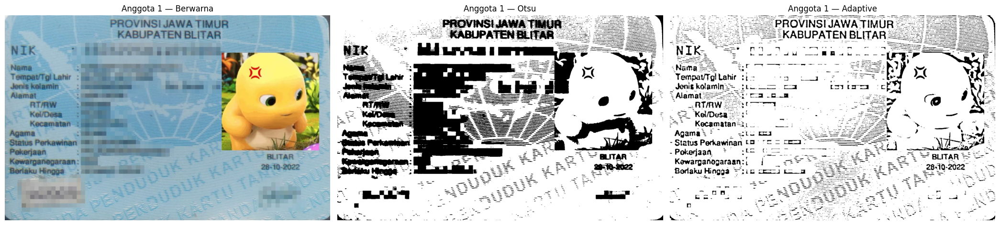

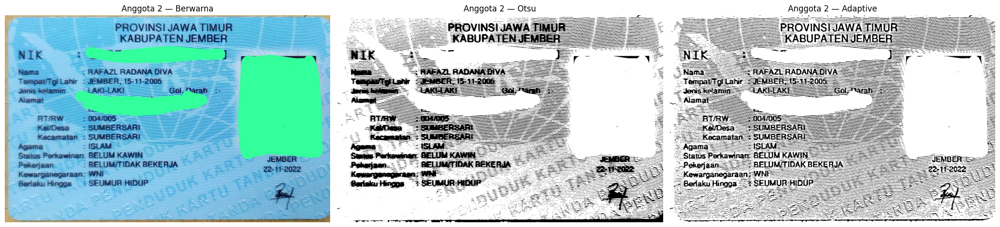

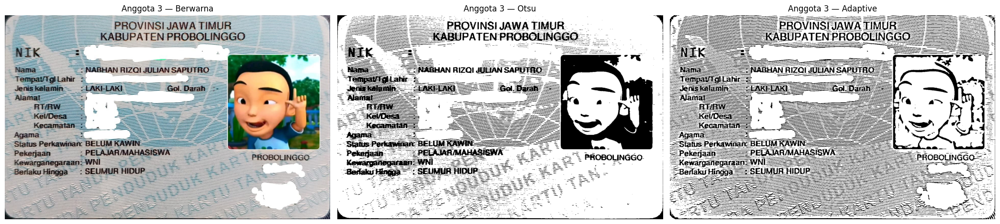

In [42]:
HASIL, CITRA = {}, {}
for nama, info in ANGGOTA.items():
    CITRA[nama] = siapkan_tiga_citra(info['file'])      # tanpa cari_path
    HASIL[nama] = {}
    for m in METODE:
        teks, d = jalankan_ocr(CITRA[nama][m])
        kotak, n_kotak = gambar_kotak(CITRA[nama][m], d)
        baca_ = [baca_item(it, teks) for it in info['acuan']]
        HASIL[nama][m] = {'teks': teks, 'kotak': kotak, 'n_kotak': n_kotak,
                          'baca': [b for b, _ in baca_], 'cocok': [c for _, c in baca_],
                          'conf': rata_conf(d)}
    print(nama, 'selesai | ukuran citra:', CITRA[nama]['Berwarna asli'].shape[:2])

for nama in ANGGOTA:
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        im = CITRA[nama][m]
        a.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap='gray', vmin=0, vmax=255)
        a.set_title(f'{nama} — {LABEL[m]}'); a.axis('off')
    plt.tight_layout(); plt.show()

Tampilkan kotak hijau

Hasil Pembacaan Teks: Anggota 1


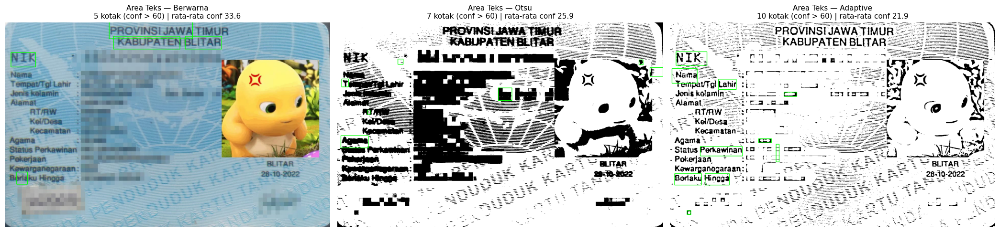

Hasil Pembacaan Teks: Anggota 2


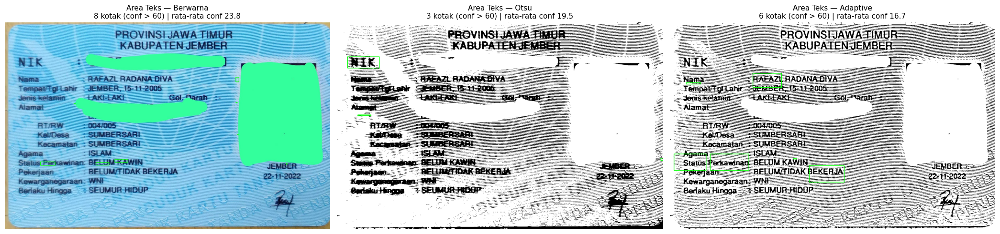

Hasil Pembacaan Teks: Anggota 3


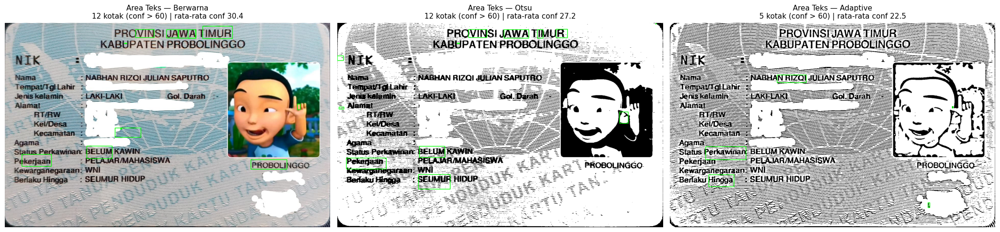

In [47]:
for nama in ANGGOTA:
    print(f'Hasil Pembacaan Teks: {nama}')
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        h = HASIL[nama][m]
        a.imshow(cv.cvtColor(h['kotak'], cv.COLOR_BGR2RGB))
        a.set_title(f"Area Teks — {LABEL[m]}\n{h['n_kotak']} kotak (conf > {CONF_MIN}) | rata-rata conf {h['conf']:.1f}", fontsize=11)
        a.axis('off')
    plt.tight_layout()
    plt.show()


In [48]:
for nama in ANGGOTA:
    print(f'\n######## {nama} ########')
    for m in METODE:
        print(f'========== {LABEL[m].upper()} ==========')
        teks = '\n'.join(l for l in HASIL[nama][m]['teks'].splitlines() if l.strip())
        print(teks)
        print()


######## Anggota 1 ########
========== BERWARNA ==========
- PROVINSIJAWA TIMUR PA
KABUPATEN BLITAR AA
NIK an nan Ti an —..
Jenikkalamin ema an Kesan om -
Alemat— — . pemmuaa AA FS
RTAWN——— Pe A
2 oria Hingga: sem — — -— 5 : 5 — 2022 5
5 "las AA — 2 — EN sa -
- . : - TA AS SAI 2

========== OTSU ==========
. . ma 5 ES Em KERS Pe EE—
Te KE Ba IE AE FE TE
. TEE — -- Pa STEP Na —— TEE T——
penata SAS Se—— 5 t-
NIK oo lara |
SES 3 — | ” v EF |
2— 2 -SSE23M F
“AA EH : AN -
T aa "Na a.. Na — )». t——
1 ».. Ia as
Meme“: gasal PA e———— ' Aa
1 A53 — —— 5 —y ' ) -
2 n—: — ai TS 5 —
T aan — : — —- . mm
5 7 —a 1 — — s5 . — -
5 SN — s — 38 css - :
aka — ——5-$sSE .
R3 " “T— AA —— ———. — .— -
: Ma - Ns CA PPN
5 — A55 —
Agama z 1. Nan BAN - SS —c 5s5-—-— «
merak “'- Mn PA Ia ai SL BLITAR
z Ted -2ELAD.. LE S S3 Ka
. Me na PN -
NN aa Men “5
—- NN FE DES " "
” NN na .
bo S Kana an 5 0. Madi an — 0 0 0 kana 25 Kan To - 0.4

========== ADAPTIVE ==========
AE En HS £ Hr SEP PE 5
2 Sasa 3 KABUPATEN BLITAR: — 

Tabel 10 item per anggota

In [44]:
TABEL = {}
for nama, info in ANGGOTA.items():
    tabel = pd.DataFrame({'No.': range(1, 11), 'Teks sebenarnya': info['acuan']})
    gaya = pd.DataFrame('', index=range(10), columns=['Teks sebenarnya'] + list(KOLOM.values()))
    for m, kol in KOLOM.items():
        tabel[kol] = HASIL[nama][m]['baca']
        gaya[kol] = ['background-color:#c8f7c5' if ok else 'background-color:#f7c5c5'
                     for ok in HASIL[nama][m]['cocok']]
    tabel = tabel.set_index('No.')
    gaya.index = tabel.index
    TABEL[nama] = tabel
    print(f'=== Tabel perbandingan {nama} (hijau = cocok, merah = tidak cocok) ===')
    display(tabel.style.apply(lambda _: gaya, axis=None))

=== Tabel perbandingan Anggota 1 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,PROVINSIJAWA,(tidak terbaca),ON SI
2,JAWA TIMUR,PROVINSIJAWA TIMUR,(tidak terbaca),(tidak terbaca)
3,KABUPATEN,KABUPATEN,(tidak terbaca),KABUPATEN
4,BLITAR,BLITAR,BLITAR,BLITAR
5,PEREMPUAN,PEMMUAA,(tidak terbaca),(tidak terbaca)
6,ISLAM,(tidak terbaca),AI SL,(tidak terbaca)
7,BELUM KAWIN,(tidak terbaca),(tidak terbaca),(tidak terbaca)
8,PELAJAR/MAHASISWA,(tidak terbaca),(tidak terbaca),(tidak terbaca)
9,WNI,NIK,NIK,NIK


=== Tabel perbandingan Anggota 2 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,PROV,PROVINSIJAWA,(tidak terbaca)
2,JAWA TIMUR,(tidak terbaca),(tidak terbaca),ROVINSIJAWATIMUR
3,KABUPATEN,KAPAN,KABUPAHENJEMBEH,KABUPATENYEMBERO
4,JEMBER,JEMPRR,SENBER,SEMBER
5,LAKI-LAKI,(tidak terbaca),(tidak terbaca),(tidak terbaca)
6,ISLAM,SAM,IA ME,JERISKELAM
7,BELUM KAWIN,BELUM KAMI,BELUM KAK,BELUM KAWIN
8,PELAJAR/MAHASISWA,(tidak terbaca),(tidak terbaca),(tidak terbaca)
9,WNI,(tidak terbaca),NIK,NI


=== Tabel perbandingan Anggota 3 (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,(tidak terbaca),VIN I,PROVINSIJAWATIMUR
2,JAWA TIMUR,WA IMUR,AA HMU,PROVINSIJAWATIMUR
3,KABUPATEN,KABUPATEN,KABUPATENP,KABUPATENPROBONNGGO
4,PROBOLINGGO,PROBOLINGGO,PHOBOLINGGO,KOBOLINGGOS
5,LAKI-LAKI,(tidak terbaca),(tidak terbaca),(tidak terbaca)
6,ISLAM,(tidak terbaca),(tidak terbaca),(tidak terbaca)
7,BELUM KAWIN,BELUM KAWAN,BELUM KAWIN,BELUM KAWIN
8,PELAJAR/MAHASISWA,PELAJAN/MAHASISWA,PELAJARIMAHASI,PELAJANMAHASISWA
9,WNI,WNI,WN,(tidak terbaca)


Ringkasan kecocokan dan confidence

In [45]:
RINGKAS = []
for nama, info in ANGGOTA.items():
    baris = []
    for m in METODE:
        h = HASIL[nama][m]
        tepat = sum(h['cocok'])
        baris.append({'Citra masukan OCR': m, 'Item terbaca tepat': f'{tepat} dari 10',
                      'Kecocokan (%)': tepat * 10.0, 'Rata-rata confidence': round(h['conf'], 1),
                      'Kotak hijau (conf > 60)': h['n_kotak']})
        RINGKAS.append({'Anggota': nama, 'Metode': m, 'Tepat': tepat,
                        'Akurasi': tepat * 10.0, 'Conf': h['conf'], 'Kotak': h['n_kotak']})
    print(f'=== Ringkasan {nama} ===')
    display(pd.DataFrame(baris).set_index('Citra masukan OCR'))

RK = pd.DataFrame(RINGKAS)
GAB = (RK.groupby('Metode', sort=False)
         .agg(Tepat=('Tepat', 'sum'), Akurasi=('Akurasi', 'mean'),
              Conf=('Conf', 'mean'), Kotak=('Kotak', 'mean'))
         .reindex(METODE))

GAB_TAMPIL = pd.DataFrame({'Item terbaca tepat': GAB['Tepat'].astype(int).astype(str) + ' dari 30',
                           'Kecocokan (%)': GAB['Akurasi'].round(1),
                           'Rata-rata confidence': GAB['Conf'].round(1)})
GAB_TAMPIL.index.name = 'Citra masukan OCR'
print('=== Ringkasan GABUNGAN seluruh anggota ===')
display(GAB_TAMPIL)

=== Ringkasan Anggota 1 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,2 dari 10,20.0,33.6,5
Segmentasi Otsu,1 dari 10,10.0,25.9,7
Segmentasi Adaptive,2 dari 10,20.0,21.9,10


=== Ringkasan Anggota 2 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,0 dari 10,0.0,23.8,8
Segmentasi Otsu,0 dari 10,0.0,19.5,3
Segmentasi Adaptive,1 dari 10,10.0,16.7,6


=== Ringkasan Anggota 3 ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,3 dari 10,30.0,30.4,12
Segmentasi Otsu,2 dari 10,20.0,27.2,12
Segmentasi Adaptive,1 dari 10,10.0,22.5,5


=== Ringkasan GABUNGAN seluruh anggota ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Citra masukan OCR,,,
Berwarna asli,5 dari 30,16.7,29.3
Segmentasi Otsu,3 dari 30,10.0,24.2
Segmentasi Adaptive,4 dari 30,13.3,20.4


1. Citra masukan mana yang menghasilkan pembacaan paling tepat?
   Citra <metode> paling tepat, yaitu <x> dari 30 item (<xx>%) dengan rata-rata
   confidence <c>. Pembanding: <metode lain> <yy>% dan <metode lain> <zz>% (lihat tabel
   ringkasan gabungan). Per anggota: Anggota 1 = <metode>, Anggota 2 = <metode>,
   Anggota 3 = <metode>.

2. Minimal dua kesalahan pembacaan (ambil dari output no. 2, sebutkan anggota dan metodenya):
   - Huruf tertukar: "<acuan>" terbaca "<hasil>" pada <anggota | metode>.
   - Kata menyatu/spasi hilang: "<acuan>" terbaca "<hasil>".
   - Teks tidak terbaca: "<acuan>" pada <anggota | metode>.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
   Tidak/Ya (pilih sesuai hasil). Otsu naik di <n> KTP, turun di <n>, sama di <n>;
   Adaptive naik di <n>, turun di <n>, sama di <n>. Jelaskan: Otsu memakai satu ambang global
   sehingga <efeknya pada KTP kalian>, sedangkan Adaptive memakai jendela lokal
   (blockSize 51, C 15) sehingga <efeknya>.

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
   KTP berlatar biru muda dengan pola peta, garis halus, dan watermark yang nilai
   keabuannya dekat dengan teks, sehingga <dampak pada citra berwarna: confidence/kecocokan
   rendah>. Setelah segmentasi, <pola latar hilang/tetap muncul sebagai bintik>. Bandingkan
   antar anggota: KTP <anggota> terbaca lebih baik karena <foto lebih tajam/latar lebih
   terang>. Dukung dengan angka dari output no. 4.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
   Secara gabungan <ya/tidak>: confidence tertinggi = <metode> (<c>), kecocokan tertinggi
   = <metode> (<xx>%). Per anggota <sama/berbeda pada ...>. Confidence hanya ukuran
   keyakinan mesin pada kata yang ia kenali, bukan jaminan kata acuan terbaca tepat.